In [49]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import missingno as msno
from plotly.subplots import make_subplots



In [50]:
df_train = pd.read_csv("data/Train.csv")
df_train.shape

(30557, 82)

In [51]:
# Bereinigten DataFrame erstellen (siehe 04_eda_justus.ipynb für die Begründung)

df_clean = df_train.copy()

# 1. Windspalten -> Windgeschwindigkeit (sqrt(u^2 + v^2))
df_clean["wind_speed"] = np.sqrt(
    df_clean["u_component_of_wind_10m_above_ground"]**2
    + df_clean["v_component_of_wind_10m_above_ground"]**2
)
df_clean = df_clean.drop(columns=[
    "u_component_of_wind_10m_above_ground",
    "v_component_of_wind_10m_above_ground",
])

# 2. Winkel-Spalten (sensor/solar azimuth/zenith) nur einmal behalten
# -> alle Gasgruppen teilen sich denselben physikalischen Winkel (gleicher Überflug),
#    daher aus der Gruppe mit den wenigsten NaNs behalten: L3_AER_AI (nur 197 von 30557 fehlend)
angle_suffixes = [
    "sensor_azimuth_angle",
    "sensor_zenith_angle",
    "solar_azimuth_angle",
    "solar_zenith_angle",
]
keep_group = "L3_AER_AI"

angle_cols_all = [c for c in df_clean.columns if c.endswith(tuple(angle_suffixes))]
angle_cols_keep = [f"{keep_group}_{suffix}" for suffix in angle_suffixes]
angle_cols_drop = [c for c in angle_cols_all if c not in angle_cols_keep]

df_clean = df_clean.drop(columns=angle_cols_drop)
df_clean = df_clean.rename(columns={
    f"{keep_group}_{suffix}": suffix for suffix in angle_suffixes
})

# 3. "_slant_column_number_density"-Spalten droppen (AMF-korrigierte "vertical"-Variante behalten)
slant_cols = [c for c in df_clean.columns if "slant_column_number_density" in c]
df_clean = df_clean.drop(columns=slant_cols)

# 4. CH4-Spalten droppen (>80% NaN)
ch4_cols = [c for c in df_clean.columns if c.startswith("L3_CH4")]
df_clean = df_clean.drop(columns=ch4_cols)

print(f"Spalten vorher: {df_train.shape[1]}, Spalten nachher: {df_clean.shape[1]}")
df_clean.info()

Spalten vorher: 82, Spalten nachher: 47
<class 'pandas.DataFrame'>
RangeIndex: 30557 entries, 0 to 30556
Data columns (total 47 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Place_ID X Date                                      30557 non-null  str    
 1   Date                                                 30557 non-null  str    
 2   Place_ID                                             30557 non-null  str    
 3   target                                               30557 non-null  float64
 4   target_min                                           30557 non-null  float64
 5   target_max                                           30557 non-null  float64
 6   target_variance                                      30557 non-null  float64
 7   target_count                                         30557 non-null  int64  
 8   precipitable_water_entire_atmosphere 

<Axes: >

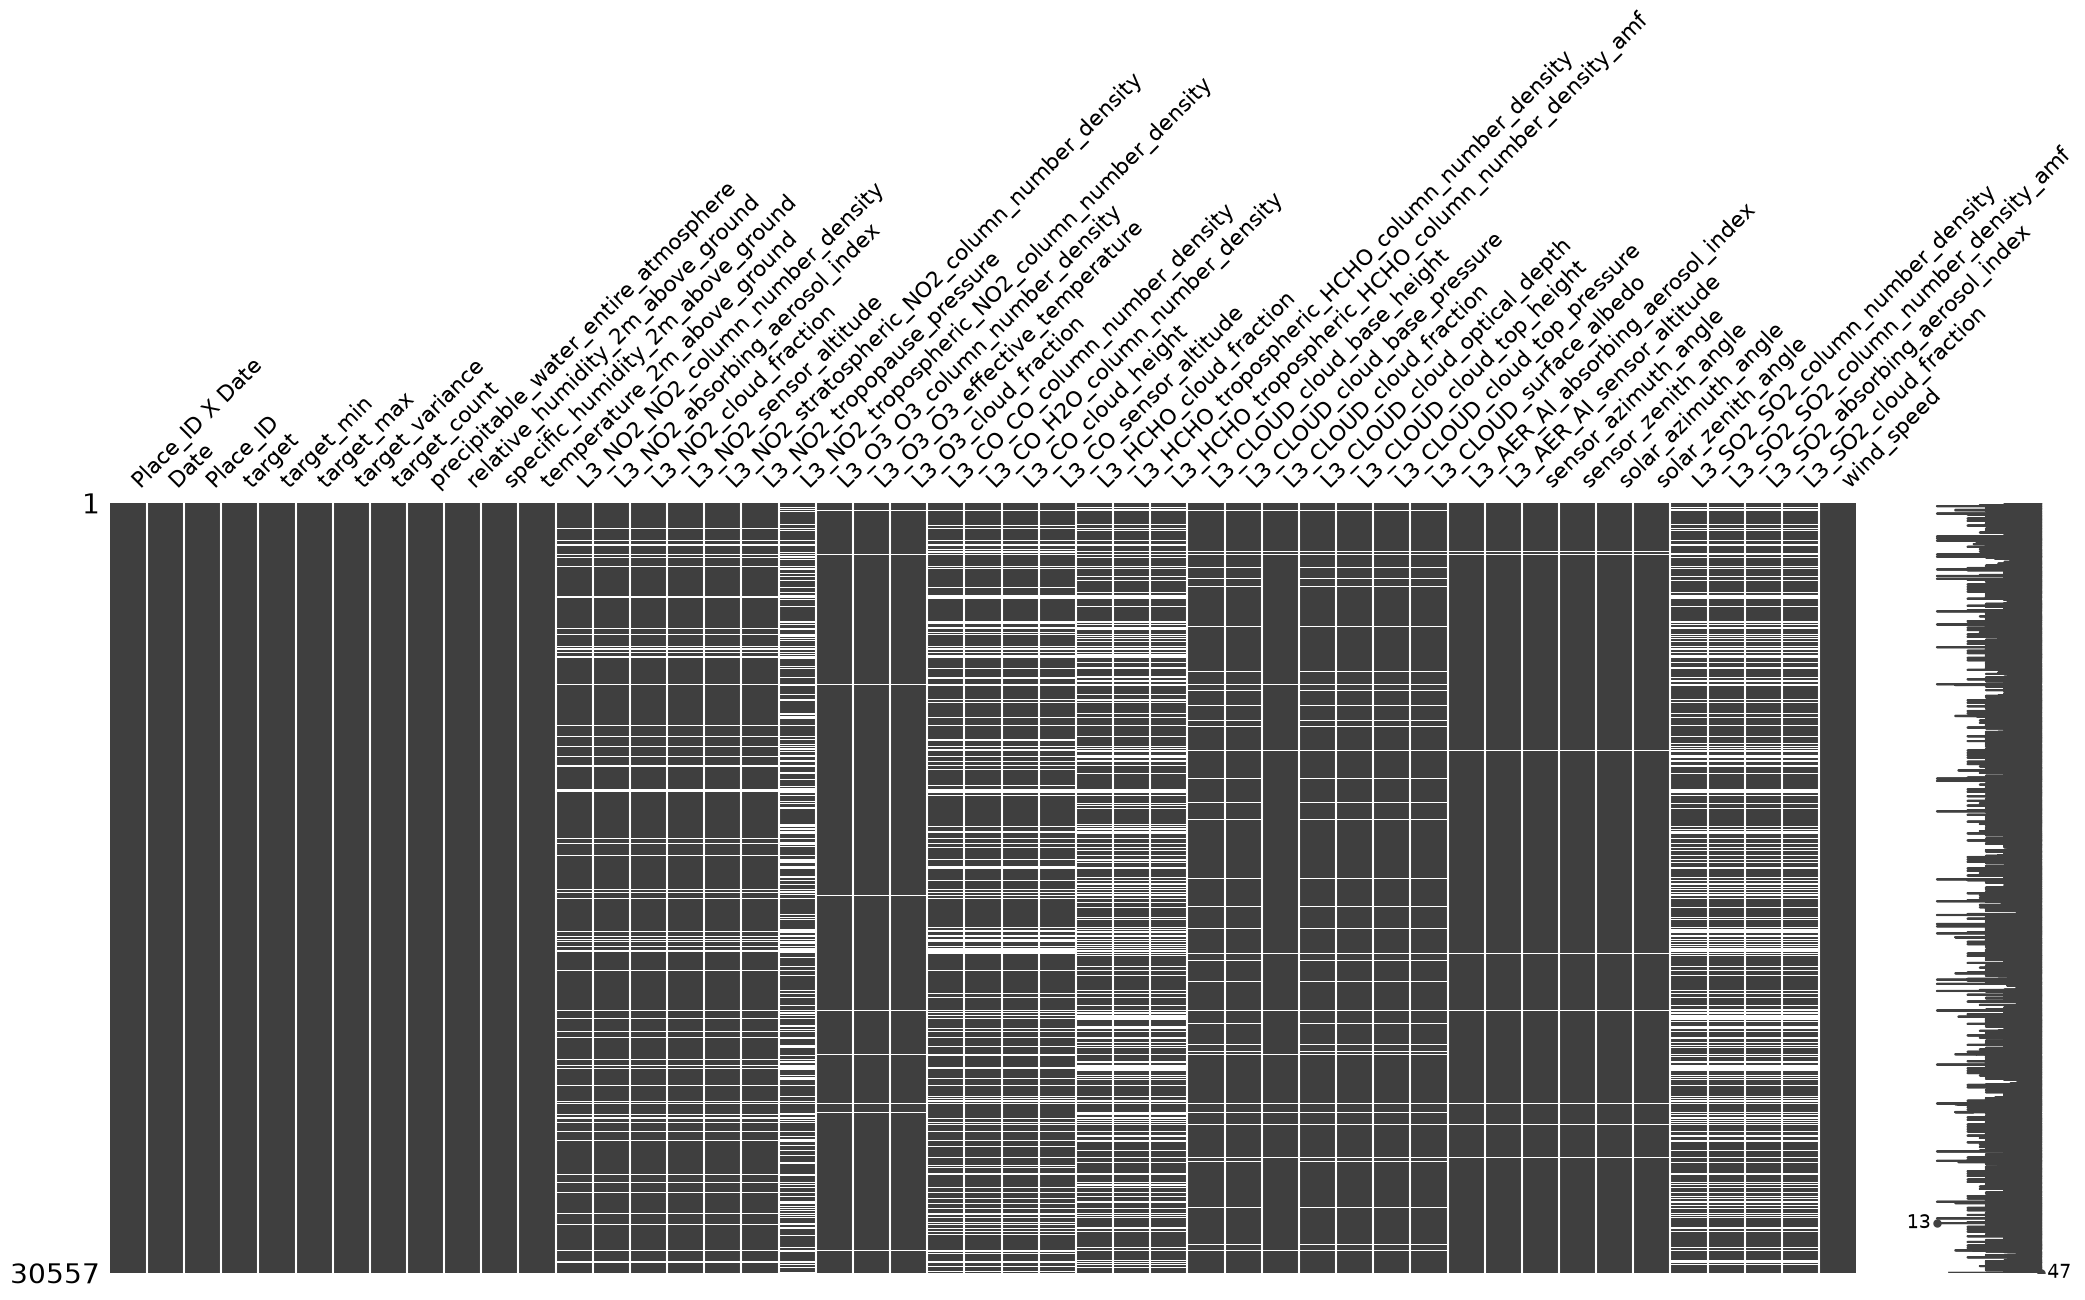

In [52]:
msno.matrix(df_clean)

In [53]:
df_clean["target_count"]

0        92
1        91
2        96
3        96
4        95
         ..
30552    72
30553    72
30554    72
30555    72
30556    72
Name: target_count, Length: 30557, dtype: int64

In [54]:
df_clean["target_count"].unique()

array([  92,   91,   96,   95,   94,   93,   85,   72,   90,   69,   81,
         80,   86,   70,   71,   82,   77,   73,   83,   55,   79,   23,
         24,   21,   22,   19,    9,   17,   11,   12,   20,   18,   64,
         33,   66,   58,   51,   48,   44,   39,   34,   67,   68,    7,
         32,   60,   40,   36,   52,   42,   38,   50,   26,   87,   76,
         63,   84,   74,   62,   59,   53,   75,   78,   89,   88,  120,
        119,  126,  142,  144,  143,  140,  141,   46,  134,  139,  138,
        130,  129,  128,  132,   47,   35,   28,   14,   41,   43,   37,
        186,  188,  182,  180,  162,  179,  189,  174,  163,  158,  190,
        187,  177,  168,  184,  160,  146,  176,  185,  166,  183,  191,
        101,  157,  171,  192,  149,  135,  175,  172,  167,  548,  571,
        531,  491,  520,  578,  576,  496,  562,  585,  587,  586,  560,
        533,  444,  489,  451,  485,  452,  484,  559,  441,  433,  486,
        376,  454,  511,  572,  540,  498,  517,  5

In [55]:
# Als CSV speichern
df_clean.to_csv("data/train_clean.csv", index=False)
print("Gespeichert unter data/train_clean.csv")

Gespeichert unter data/train_clean.csv


## Imputation: zeitliche Interpolation (Luecke < 3 Tage) + Orts-Median als Fallback

Strategie:
1. Bekannte Sensorausfaelle (exakte 0 in der Hauptmessgroesse einer L3-Gruppe: NO2, O3, CO, HCHO, SO2) werden zuerst auf NaN gesetzt, damit sie nicht als echte Messwerte interpoliert/gemittelt werden (siehe Begruendung bei `df_imputed_median` weiter unten).
2. Pro Ort (`Place_ID`) zeitbasiert interpolieren (`method="time"`, respektiert echte Kalenderabstaende, auch wenn einzelne Kalendertage als ganze Zeile fehlen) - aber NUR wenn die Luecke zwischen zwei vorhandenen Messungen kleiner als 3 Tage ist (also 1-2 fehlende Tage dazwischen).
3. Alles, was danach noch fehlt (Luecke >= 3 Tage, oder Rand-Luecken vor der ersten/nach der letzten Messung eines Ortes), wird mit dem **Median dieses Ortes** aufgefuellt.
4. Letzter Rueckfall: falls eine Spalte fuer einen Ort komplett fehlt (Orts-Median selbst ist NaN), globaler Median ueber alle Orte.


In [56]:
# Gap-aware zeitliche Interpolation (nur Luecken < 3 Tage) je Ort

df_imputed_interp = df_clean.copy()
df_imputed_interp["Date"] = pd.to_datetime(df_imputed_interp["Date"])
df_imputed_interp = df_imputed_interp.sort_values(["Place_ID", "Date"]).reset_index(drop=True)

# Bekannte Sensorausfaelle: exakte 0 in der Hauptmessgroesse einer L3-Gruppe -> ganze Gruppe
# (gleiche Zeile) auf NaN setzen, da sie dann ausnahmslos ebenfalls exakt 0 sind
gas_group_main_col = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}
n_zero_rows_total = 0
for prefix, main_col in gas_group_main_col.items():
    group_cols = [c for c in df_imputed_interp.columns if c.startswith(prefix)]
    failure_mask = df_imputed_interp[main_col] == 0
    n_zero_rows_total += failure_mask.sum()
    df_imputed_interp.loc[failure_mask, group_cols] = np.nan

print(f"Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: {n_zero_rows_total}")

cols_to_impute = df_imputed_interp.columns[df_imputed_interp.isna().any()].tolist()
print(f"{len(cols_to_impute)} Spalten mit fehlenden Werten:")
print(cols_to_impute)

MAX_GAP_DAYS = 2  # "Luecke < 3 Tage" -> 1 oder 2 fehlende Tage dazwischen werden interpoliert


def interpolate_short_gaps(group_df, col, max_gap_days=MAX_GAP_DAYS):
    s = group_df.set_index("Date")[col].sort_index()

    valid_dates = s.dropna().index
    if len(valid_dates) == 0:
        return s.values  # ganze Spalte fuer diesen Ort fehlt -> Median-Fallback uebernimmt spaeter

    date_lookup = pd.Series(valid_dates, index=valid_dates)
    prev_valid = date_lookup.reindex(s.index, method="ffill")
    next_valid = date_lookup.reindex(s.index, method="bfill")
    gap_days = (next_valid - prev_valid).dt.days

    s_interp = s.interpolate(method="time", limit_area="inside")

    is_na = s.isna()
    fill_mask = is_na & prev_valid.notna() & next_valid.notna() & (gap_days <= max_gap_days)

    result = s.copy()
    result[fill_mask] = s_interp[fill_mask]
    return result.values


n_before = df_imputed_interp[cols_to_impute].isna().sum().sum()

for col in cols_to_impute:
    parts = []
    for place_id, group in df_imputed_interp.groupby("Place_ID", sort=False):
        parts.append(pd.Series(interpolate_short_gaps(group, col), index=group.index))
    df_imputed_interp[col] = pd.concat(parts).sort_index()

n_after_interp = df_imputed_interp[cols_to_impute].isna().sum().sum()
print(f"NaNs vor Interpolation (inkl. markierter Sensorausfaelle): {n_before}")
print(f"NaNs nach Interpolation (Luecken < 3 Tage gefuellt): {n_after_interp} "
      f"({(n_before - n_after_interp) / n_before:.1%} durch Interpolation gefuellt)")


Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: 4254
34 Spalten mit fehlenden Werten:
['L3_NO2_NO2_column_number_density', 'L3_NO2_absorbing_aerosol_index', 'L3_NO2_cloud_fraction', 'L3_NO2_sensor_altitude', 'L3_NO2_stratospheric_NO2_column_number_density', 'L3_NO2_tropopause_pressure', 'L3_NO2_tropospheric_NO2_column_number_density', 'L3_O3_O3_column_number_density', 'L3_O3_O3_effective_temperature', 'L3_O3_cloud_fraction', 'L3_CO_CO_column_number_density', 'L3_CO_H2O_column_number_density', 'L3_CO_cloud_height', 'L3_CO_sensor_altitude', 'L3_HCHO_cloud_fraction', 'L3_HCHO_tropospheric_HCHO_column_number_density', 'L3_HCHO_tropospheric_HCHO_column_number_density_amf', 'L3_CLOUD_cloud_base_height', 'L3_CLOUD_cloud_base_pressure', 'L3_CLOUD_cloud_fraction', 'L3_CLOUD_cloud_optical_depth', 'L3_CLOUD_cloud_top_height', 'L3_CLOUD_cloud_top_pressure', 'L3_CLOUD_surface_albedo', 'L3_AER_AI_absorbing_aerosol_index', 'L3_AER_AI_sensor_altitude', 'sensor_azimuth_an

In [57]:
# Verbleibende Luecken (>= 3 Tage, Rand-Luecken) mit Orts-Median auffuellen,
# letzter Rueckfall: globaler Median

for col in cols_to_impute:
    df_imputed_interp[col] = df_imputed_interp[col].fillna(df_imputed_interp.groupby("Place_ID")[col].transform("median"))

n_after_median = df_imputed_interp[cols_to_impute].isna().sum().sum()
print(f"NaNs nach Orts-Median-Fallback: {n_after_median}")

for col in cols_to_impute:
    df_imputed_interp[col] = df_imputed_interp[col].fillna(df_imputed_interp[col].median())

n_final = df_imputed_interp[cols_to_impute].isna().sum().sum()
print(f"NaNs final: {n_final}")

df_imputed_interp.to_csv("data/train_imputed_interp.csv", index=False)
print("Gespeichert unter data/train_imputed.csv")


NaNs nach Orts-Median-Fallback: 61
NaNs final: 0
Gespeichert unter data/train_imputed.csv


## Alternative Imputationsstrategie: reiner Orts-Median (ohne Interpolation)

Als Vergleich zu `df_imputed_interp`: hier wird jeder fehlende Wert direkt mit dem **Median des jeweiligen Ortes (`Place_ID`)** gefuellt, ohne vorherige zeitliche Interpolation. Fallback bei komplett fehlenden Orts-Spalten: globaler Median.

**Zusaetzlich:** exakte `0.000000`-Werte sind in den L3-Schadstoffgruppen (NO2, O3, CO, HCHO, SO2) kein Messwert, sondern ein Sensor-/Pipeline-Ausfall - wenn die Hauptmessgroesse einer Gruppe exakt 0 ist, sind in derselben Zeile ausnahmslos ALLE Spalten dieser Gruppe ebenfalls exakt 0 (geprueft z.B. fuer NO2: 2611 von 2611 betroffenen Zeilen). Diese Werte werden vor der Median-Imputation auf NaN gesetzt und dann wie echte fehlende Werte behandelt. `cloud_fraction` und die Winkel-Spalten sind davon ausgenommen, da 0 dort ein legitimer physikalischer Wert sein kann (z.B. klarer Himmel).


In [58]:
# Reine Orts-Median-Imputation (keine Interpolation)

df_imputed_median = df_clean.copy()

# Bekannte Sensorausfaelle: exakte 0 in der Hauptmessgroesse einer L3-Gruppe -> ganze Gruppe
# (gleiche Zeile) auf NaN setzen, da sie dann ausnahmslos ebenfalls exakt 0 sind
gas_group_main_col = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}

n_zero_rows_total = 0
for prefix, main_col in gas_group_main_col.items():
    group_cols = [c for c in df_imputed_median.columns if c.startswith(prefix)]
    failure_mask = df_imputed_median[main_col] == 0
    n_zero_rows_total += failure_mask.sum()
    df_imputed_median.loc[failure_mask, group_cols] = np.nan

print(f"Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: {n_zero_rows_total}")

cols_to_impute_median = df_imputed_median.columns[df_imputed_median.isna().any()].tolist()
n_before_median = df_imputed_median[cols_to_impute_median].isna().sum().sum()

for col in cols_to_impute_median:
    df_imputed_median[col] = df_imputed_median[col].fillna(
        df_imputed_median.groupby("Place_ID")[col].transform("median")
    )

n_after_place_median = df_imputed_median[cols_to_impute_median].isna().sum().sum()
print(f"NaNs vor Imputation (inkl. markierter Sensorausfaelle): {n_before_median}")
print(f"NaNs nach Orts-Median: {n_after_place_median}")

# Letzter Rueckfall: globaler Median (falls eine Spalte fuer einen Ort komplett fehlt)
for col in cols_to_impute_median:
    df_imputed_median[col] = df_imputed_median[col].fillna(df_imputed_median[col].median())

n_final_median = df_imputed_median[cols_to_impute_median].isna().sum().sum()
print(f"NaNs final: {n_final_median}")

df_imputed_median.to_csv("data/train_imputed_median.csv", index=False)
print("Gespeichert unter data/train_imputed_median.csv")


Als Sensorausfall markierte Zeilen (0 -> NaN), aufsummiert ueber alle Gruppen: 4254
NaNs vor Imputation (inkl. markierter Sensorausfaelle): 130194
NaNs nach Orts-Median: 61
NaNs final: 0
Gespeichert unter data/train_imputed_median.csv


<Axes: >

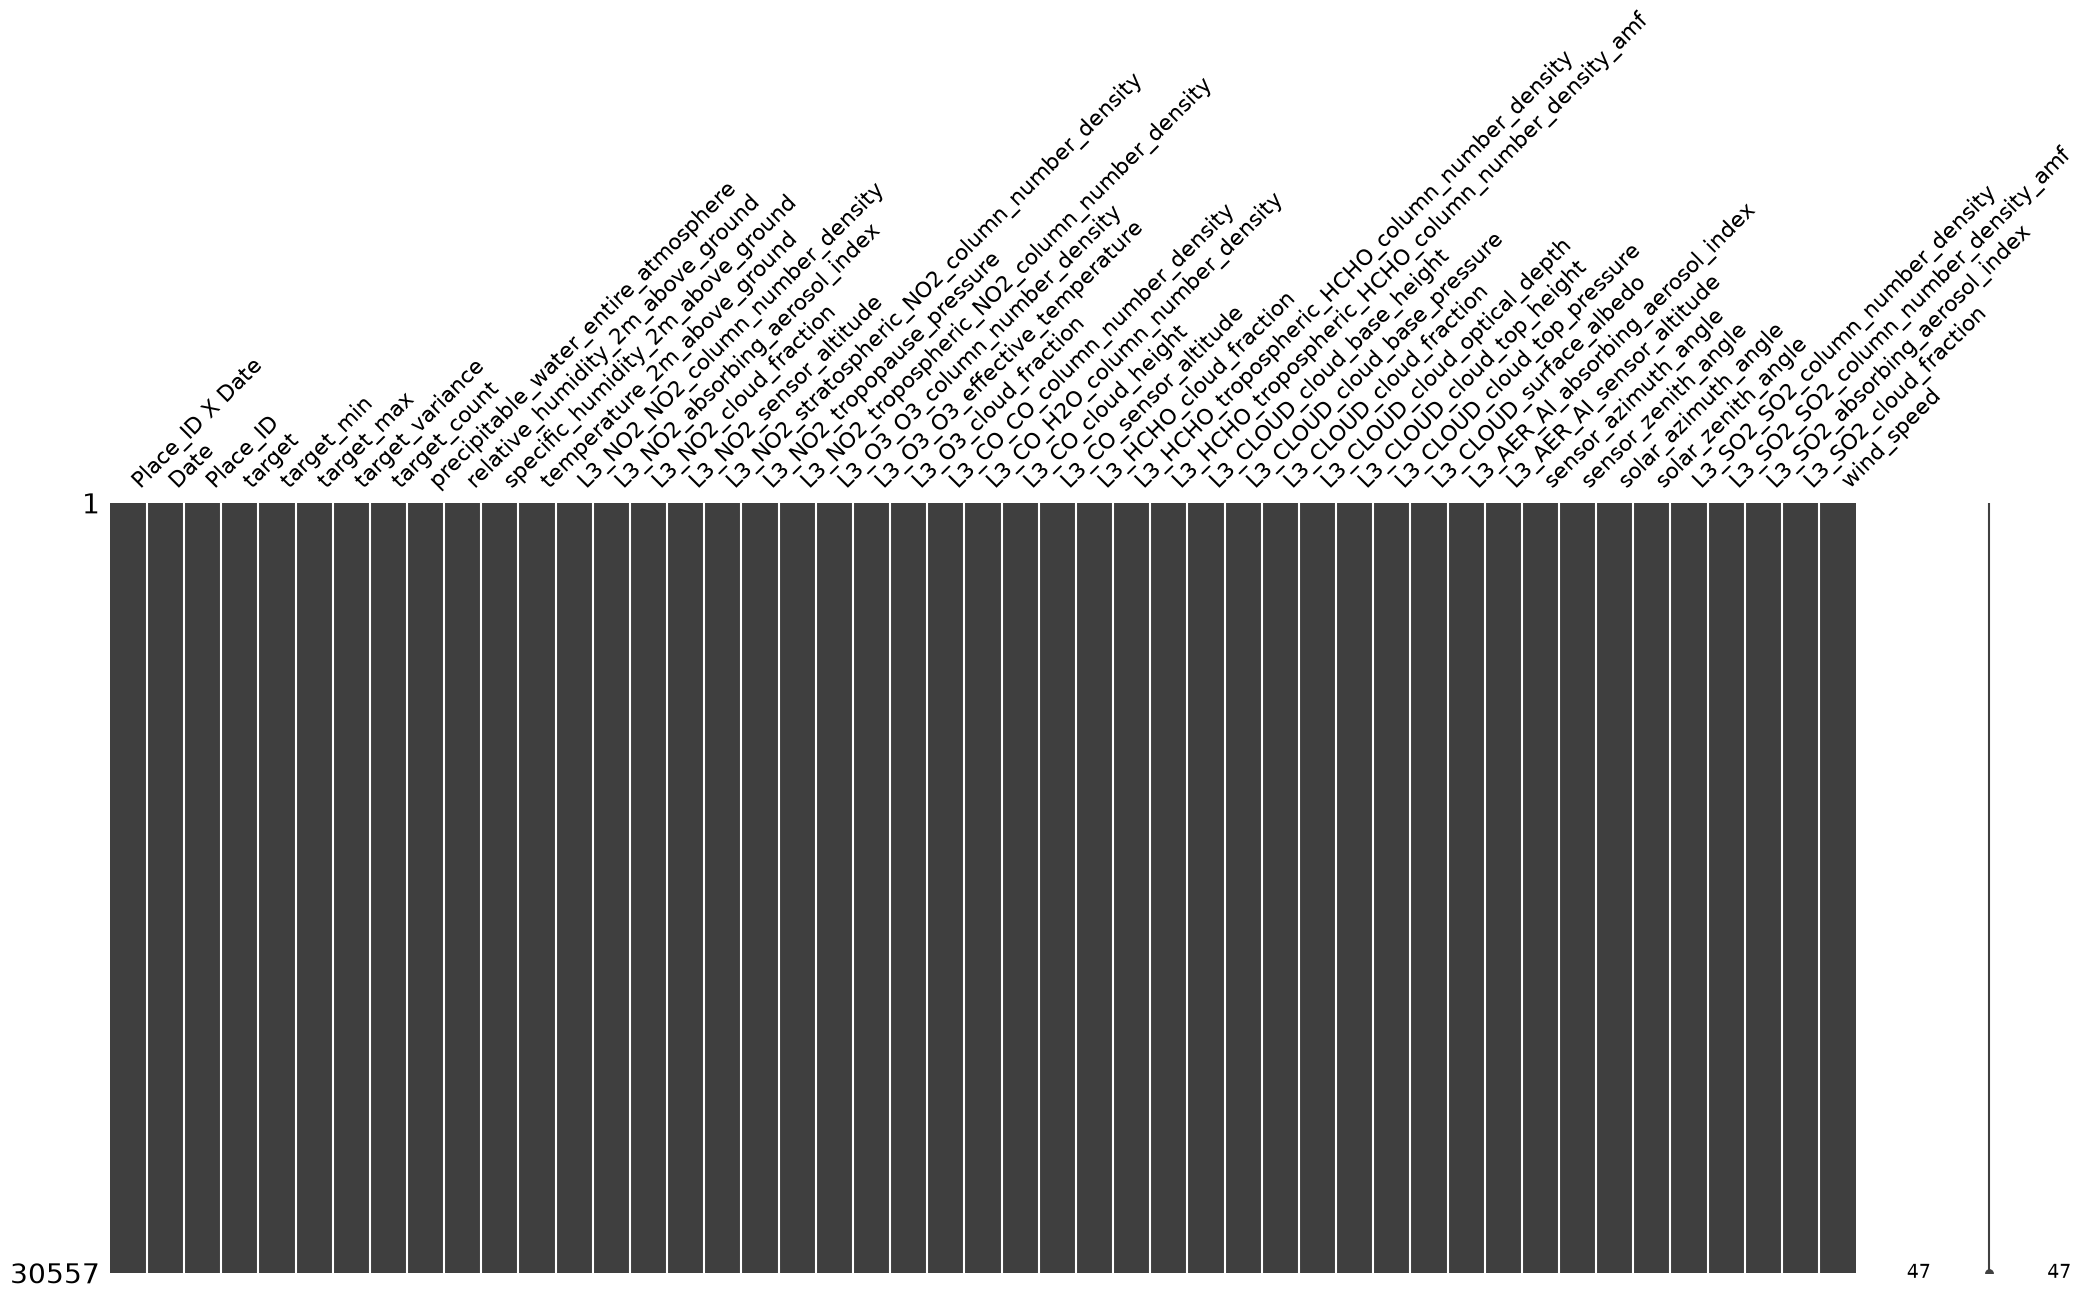

In [59]:
msno.matrix(df_imputed_median)

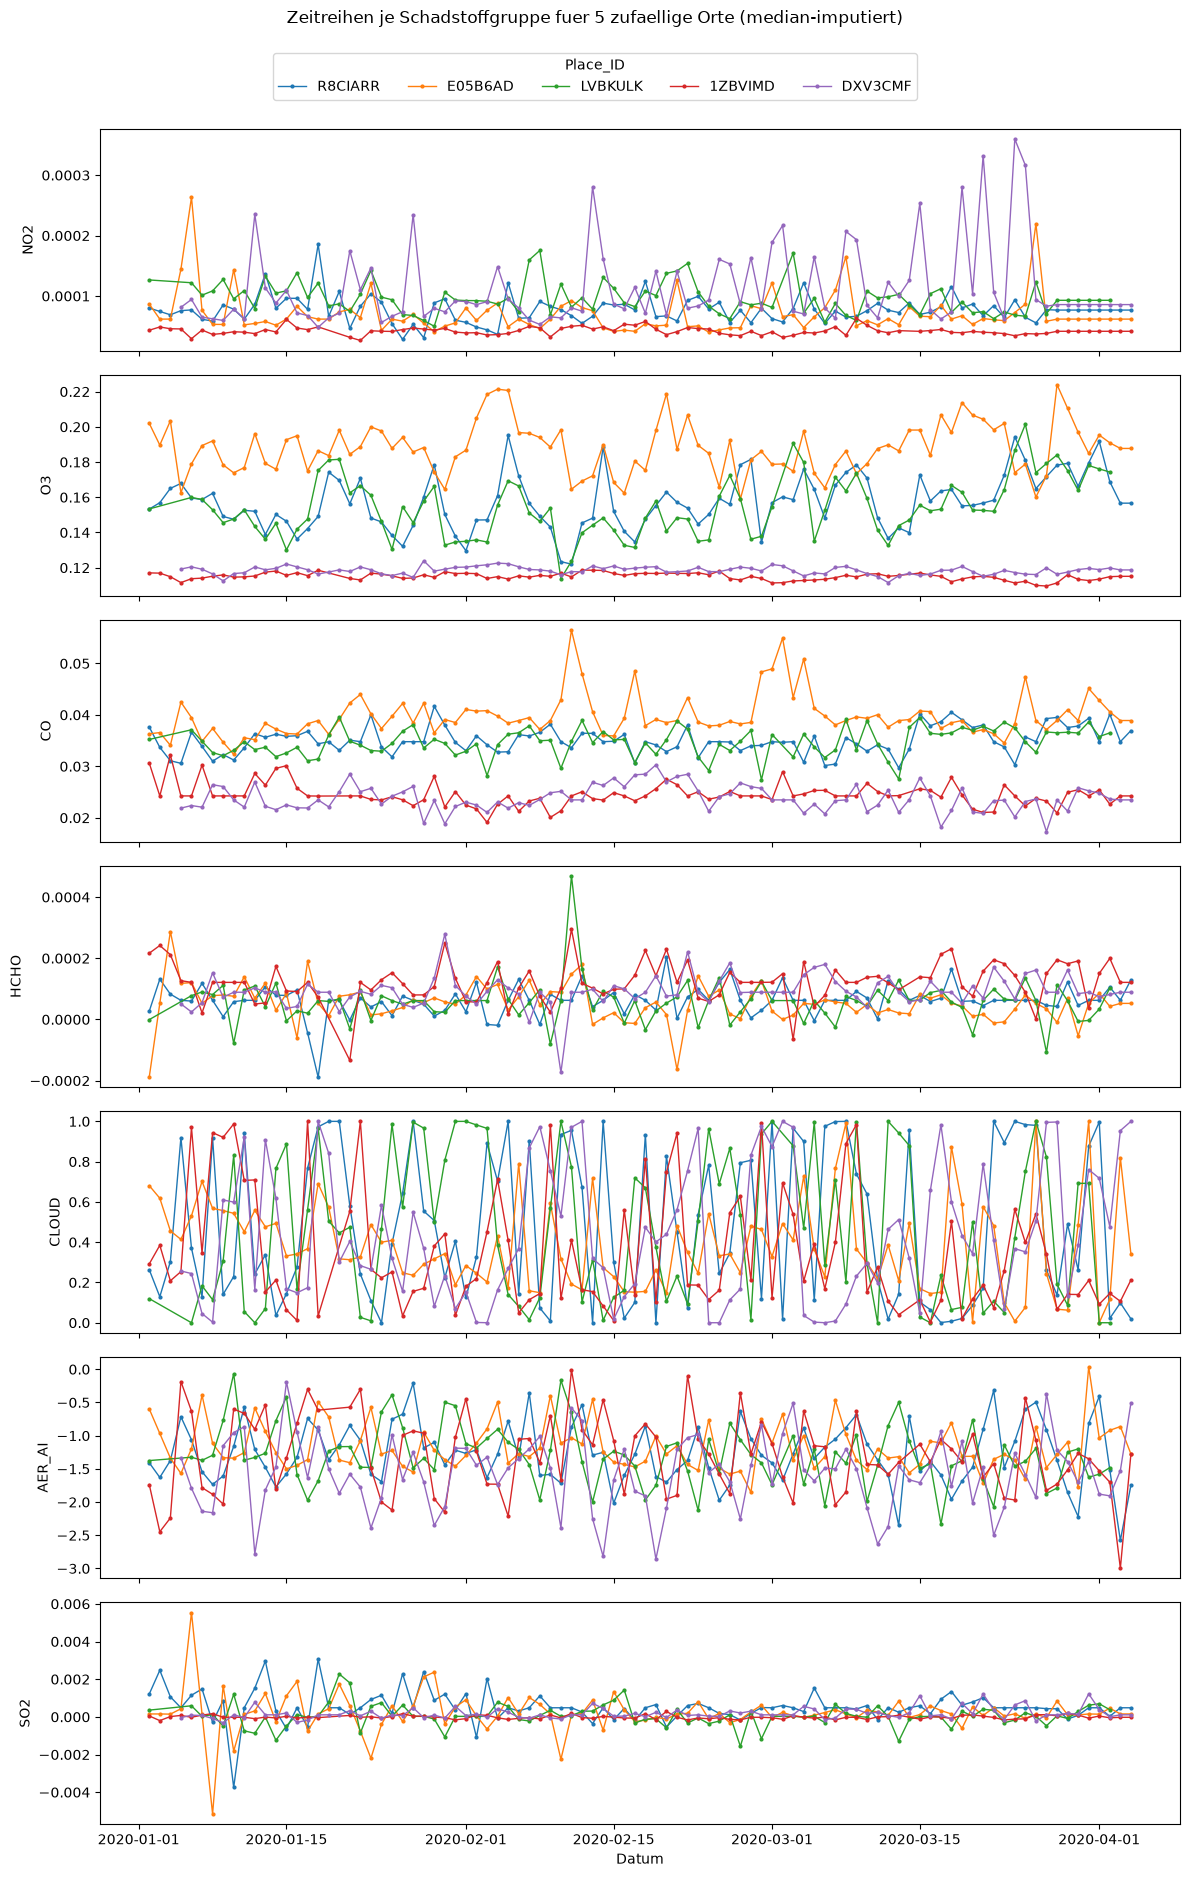

In [60]:
# Zeitreihen je Schadstoffgruppe fuer 5 zufaellige Orte (df_imputed_median, bereits median-imputiert)
# -> kein reindex auf vollstaendigen Tagesraster, da fuer manche Orte ganze Kalendertage als
#    Zeile fehlen (nicht nur NaN-Werte) - ein reindex wuerde dafuer kuenstlich neue, leere
#    Zeilen erzeugen und so faelschlich wieder Luecken zeigen, obwohl die Imputation
#    alle vorhandenen Zeilen bereits vollstaendig gefuellt hat.

gas_repr_cols = {
    "NO2": "L3_NO2_NO2_column_number_density",
    "O3": "L3_O3_O3_column_number_density",
    "CO": "L3_CO_CO_column_number_density",
    "HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "CLOUD": "L3_CLOUD_cloud_fraction",
    "AER_AI": "L3_AER_AI_absorbing_aerosol_index",
    "SO2": "L3_SO2_SO2_column_number_density",
}

# 5 zufaellige Orte auswaehlen (fester Seed fuer Reproduzierbarkeit)
rng = np.random.default_rng(42)
size = 5
random_places = rng.choice(df_imputed_median["Place_ID"].unique(), size, replace=False)

palette = sns.color_palette("tab10", n_colors=len(random_places))
place_colors = dict(zip(random_places, palette))

fig, axes = plt.subplots(len(gas_repr_cols), 1, figsize=(12, 18), sharex=True)

for ax, (gas, col) in zip(axes, gas_repr_cols.items()):
    for place_id in random_places:
        df_place = df_imputed_median[df_imputed_median["Place_ID"] == place_id].copy()
        df_place["Date"] = pd.to_datetime(df_place["Date"])
        df_place = df_place.sort_values("Date")
        ax.plot(
            df_place["Date"], df_place[col],
            marker="o", markersize=2, linewidth=1,
            color=place_colors[place_id], label=place_id,
        )
    ax.set_ylabel(gas)

axes[-1].set_xlabel("Datum")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Place_ID", loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5)
fig.suptitle("Zeitreihen je Schadstoffgruppe fuer " + str(size) + " zufaellige Orte (median-imputiert)", y=1.04)
plt.tight_layout()
plt.show()


In [63]:
# Imputation mit Median von jeweiligem Monat + Missing-Indicator-Flags
df_imputed_month_median = df_clean.copy()
df_imputed_month_median["Date"] = pd.to_datetime(df_imputed_month_median["Date"])
df_imputed_month_median["Month"] = df_imputed_month_median["Date"].dt.month

# Bekannte Sensorausfaelle (exakte 0 in der Hauptmessgroesse einer L3-Gruppe) auf NaN setzen,
# damit sie nicht als echte Messwerte in den Monats-Median einfliessen
gas_group_main_col = {
    "L3_NO2": "L3_NO2_NO2_column_number_density",
    "L3_O3": "L3_O3_O3_column_number_density",
    "L3_CO": "L3_CO_CO_column_number_density",
    "L3_HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_SO2": "L3_SO2_SO2_column_number_density",
}
for prefix, main_col in gas_group_main_col.items():
    group_cols = [c for c in df_imputed_month_median.columns if c.startswith(prefix)]
    failure_mask = df_imputed_month_median[main_col] == 0
    df_imputed_month_median.loc[failure_mask, group_cols] = np.nan

cols_to_impute = df_imputed_month_median.columns[df_imputed_month_median.isna().any()].tolist()
print(f"{len(cols_to_impute)} Spalten mit fehlenden Werten (inkl. markierter Sensorausfaelle)")

# Missing-Indicator-Flags VOR der Imputation anlegen, damit das Modell echte Infolage
# (z.B. Wolken-bedingte Ausfaelle) separat von den tatsaechlich gefuellten Werten sehen kann
for col in cols_to_impute:
    df_imputed_month_median[f"{col}_missing"] = df_imputed_month_median[col].isna()

n_before = df_imputed_month_median[cols_to_impute].isna().sum().sum()

# 1. Median je Ort + Monat (feinere Granularitaet als reiner Orts-Median, erfasst Saisonalitaet)
for col in cols_to_impute:
    df_imputed_month_median[col] = df_imputed_month_median[col].fillna(
        df_imputed_month_median.groupby(["Place_ID", "Month"])[col].transform("median")
    )
n_after_month = df_imputed_month_median[cols_to_impute].isna().sum().sum()

# 2. Fallback: reiner Orts-Median (falls eine Ort+Monat-Kombination komplett fehlt)
for col in cols_to_impute:
    df_imputed_month_median[col] = df_imputed_month_median[col].fillna(
        df_imputed_month_median.groupby("Place_ID")[col].transform("median")
    )
n_after_place = df_imputed_month_median[cols_to_impute].isna().sum().sum()

# 3. Letzter Rueckfall: globaler Median
for col in cols_to_impute:
    df_imputed_month_median[col] = df_imputed_month_median[col].fillna(df_imputed_month_median[col].median())
n_final = df_imputed_month_median[cols_to_impute].isna().sum().sum()

print(f"NaNs vor Imputation: {n_before}")
print(f"NaNs nach Orts+Monats-Median: {n_after_month}")
print(f"NaNs nach Orts-Median-Fallback: {n_after_place}")
print(f"NaNs final: {n_final}")

df_imputed_month_median = df_imputed_month_median.drop(columns=["Month"])
df_imputed_month_median.to_csv("data/train_imputed_month_median.csv", index=False)
print("Gespeichert unter data/train_imputed_month_median.csv")


34 Spalten mit fehlenden Werten (inkl. markierter Sensorausfaelle)
NaNs vor Imputation: 130194
NaNs nach Orts+Monats-Median: 11539
NaNs nach Orts-Median-Fallback: 61
NaNs final: 0
Gespeichert unter data/train_imputed_month_median.csv


## Baseline-Modell: Lineare Regression mit Top-Features je Imputationsstrategie

Einfaches lineares Regressions-Baseline mit den 4 am staerksten korrelierten Features (`wind_speed`, HCHO-, CO-, NO2-Column-Density, siehe 04_eda_justus.ipynb) **plus Zielkodierung von `Place_ID`** (Out-of-Fold-Mittelwert des Targets je Ort, 5-Fold, um Leakage zu vermeiden - `Place_ID` erklaert laut Eta^2-Analyse allein schon 14% der Varianz), einmal pro Imputations-Variante (`df_imputed_interp`, `df_imputed_median`, `df_imputed_month_median`), um die Strategien anhand der tatsaechlichen Modellguete (nicht nur NaN-Anzahl) zu vergleichen.

**Wichtig:** Der Split unten ist ein interner Validierungs-Split *innerhalb von `Train.csv`* (80/20, gleicher `random_state` fuer Vergleichbarkeit) - NICHT die echte `data/Test.csv` (die hat kein `target` und wird erst spaeter fuer die eigentliche Submission verwendet). Deshalb heissen die Variablen hier bewusst `val` statt `test`. Evaluationsmetriken: RMSE und R^2.


In [ ]:
# Baseline: Lineare Regression mit Top-Features + Place_ID-Zielkodierung, je Imputationsstrategie
#
# Hinweis: "val" bezeichnet hier einen Validierungs-Split INNERHALB von Train.csv, nicht die
# externe data/Test.csv (die kein target enthaelt und erst spaeter fuer die Submission genutzt wird).
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import root_mean_squared_error, r2_score

features = [
    "wind_speed",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_NO2_NO2_column_number_density",
]


def add_place_target_encoding(train_df, val_df, place_col="Place_ID", target_col="target",
                               n_splits=5, random_state=42):
    """Out-of-Fold Zielkodierung: vermeidet Leakage, da kein Trainings-Fold seine eigenen
    Target-Werte zur Berechnung der eigenen Kodierung verwendet. Fuer den Validierungs-Split wird
    der volle Trainings-Mittelwert je Ort genutzt (dessen Targets fliessen nie in die Kodierung ein)."""
    global_mean = train_df[target_col].mean()
    train_enc = pd.Series(index=train_df.index, dtype=float)

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    for fit_idx, hold_idx in kf.split(train_df):
        fit_part = train_df.iloc[fit_idx]
        hold_part = train_df.iloc[hold_idx]
        place_means = fit_part.groupby(place_col)[target_col].mean()
        train_enc.iloc[hold_idx] = hold_part[place_col].map(place_means).fillna(global_mean).values

    place_means_full = train_df.groupby(place_col)[target_col].mean()
    val_enc = val_df[place_col].map(place_means_full).fillna(global_mean)

    return train_enc.values, val_enc.values


datasets = {
    "interp + Orts-Median": df_imputed_interp,
    "reiner Orts-Median": df_imputed_median,
    "Orts+Monats-Median": df_imputed_month_median,
}

results = []
for name, df in datasets.items():
    df_train_part, df_val_part = train_test_split(df, test_size=0.2, random_state=42)

    place_enc_train, place_enc_val = add_place_target_encoding(df_train_part, df_val_part)

    X_train = df_train_part[features].copy()
    X_train["place_target_enc"] = place_enc_train
    y_train = df_train_part["target"]

    X_val = df_val_part[features].copy()
    X_val["place_target_enc"] = place_enc_val
    y_val = df_val_part["target"]

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    rmse = root_mean_squared_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    results.append({"Imputationsstrategie": name, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results)
results_df
